# Breast Ultrasound Lesion Classification: Segmentation-Guided Radiomics and Deep-Feature Fusion

Fully automatic benign-versus-malignant classification of breast ultrasound lesions.
A UNet++ (EfficientNet-B3) segments each lesion; 18 handcrafted radiomic features and
2048 fixed deep features from a frozen ImageNet ResNet-50 (no fine-tuning) are extracted
from the predicted ROI and combined in a sparse logistic model. Models are trained on
**BUSI** and validated externally on **BUS-BRA**.

```
BUSI ─ pHash dedup ─┬─► UNet++ segmentation (Dice / IoU)
                    └─► predicted-mask ROI ─┬─► radiomics (18) ──────────┐
                                            └─► frozen ResNet-50 (2048) ─┴─► LASSO → LR
BUS-BRA ────────────────────────────────────────────────────────────────► external test
```

This notebook is the run that produced the published results and is saved with its
outputs. It was executed on Google Colab (A100). To reproduce the numbers exactly, place
the released segmentation checkpoint (`unet_best.pt`) in the working directory and the
two feature caches (`features_internal_pred.joblib`, `features_external_pred.joblib`) in
`CONFIG["results_dir"]`; the notebook then loads them instead of retraining. See the
repository README for details.

## 1. Data

**BUSI (train + internal test)** — 780 images, benign/malignant/normal, with masks.
- Kaggle: https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset
- Folder after unzip: `Dataset_BUSI_with_GT/{benign,malignant,normal}/` with
  `name (i).png` and `name (i)_mask.png` (occasionally `..._mask_1.png`).

**BUS-BRA (external validation)** — larger, different scanners, with pathology + BI-RADS.
- Kaggle: https://www.kaggle.com/datasets/orvile/bus-bra-a-breast-ultrasound-dataset
- Zenodo (original): https://zenodo.org/records/8231412
- Typically: `Images/`, `Masks/`, and a CSV (e.g. `bus_data.csv`) with a pathology
  column (benign/malignant) and BI-RADS.

Neither dataset is redistributed here. Cite Al-Dhabyani et al. (2020) for BUSI and
Gómez-Flores et al. (2024) for BUS-BRA, and set the two dataset paths in `CONFIG` below.

## 2. Setup

In [ ]:
# Dependencies. PyRadiomics is deliberately not installed: the published results use the
# scikit-image radiomics backend (18 first-order, GLCM and shape features).
%pip install -q segmentation-models-pytorch imagehash opencv-python-headless scikit-image \
    scikit-learn pandas matplotlib tqdm shap albumentations scipy


In [ ]:
import os, glob, re, random, warnings, hashlib
import numpy as np, pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CONFIG = {
    # dataset locations (Colab paths used for the published run)
    "busi_root":   "/content/Dataset_BUSI_with_GT",
    "busbra_root": "/content/BUS_BRA DATASET",
    "img_size":    256,
    "epochs":      40,
    "batch_size":  8,
    "lr":          1e-4,
    "arch":        "UnetPlusPlus",
    "encoder":     "efficientnet-b3",
    "weight_decay":1e-4,
    "seg_tta":     True,             # test-time augmentation at inference
    "seg_loss":    "focal_tversky",  # "focal_tversky" or "dice_focal"
    "tversky_alpha": 0.3,            # false-positive weight
    "tversky_beta":  0.7,            # false-negative weight (>alpha penalizes missed lesions)
    "tversky_gamma": 1.33,           # focal exponent (>1 focuses on hard cases)
    "cnn_backbone":"resnet50",
    "test_frac":   0.2,
    "val_frac":    0.15,
    "roi_pad":     0.15,     # padding around mask bbox when cropping the CNN ROI
    "n_folds":     5,        # stratified k-fold for the classification CV
    "results_dir": "/content/results",
    "save_to_drive": False,  # set True to also copy the results zip into Drive
    "drive_results": "/content/drive/MyDrive/breast_us_results",
    "ext_use_pred_mask": True,        # external ROIs from predicted masks (fully automatic)
    "internal_use_pred_mask": True,   # internal ROIs from predicted masks (fully automatic)
}
os.makedirs(CONFIG["results_dir"], exist_ok=True)
print("device:", DEVICE, "| results ->", CONFIG["results_dir"])

device: cuda | results -> /content/results


## 3. Index BUSI

Multi-part masks are merged into one lesion mask per image.

In [ ]:
def index_busi(root):
    rows = []
    for cls in ["benign", "malignant", "normal"]:
        d = os.path.join(root, cls)
        if not os.path.isdir(d):
            continue
        imgs = [f for f in glob.glob(os.path.join(d, "*.png")) if "_mask" not in f]
        for ip in sorted(imgs):
            base = os.path.splitext(os.path.basename(ip))[0]
            masks = sorted(glob.glob(os.path.join(d, f"{base}_mask*.png")))
            rows.append({"image": ip, "masks": masks, "class": cls})
    df = pd.DataFrame(rows)
    if df.empty:
        raise FileNotFoundError(
            f"No BUSI images found under {root}. Check CONFIG['busi_root'].")
    return df

busi = index_busi(CONFIG["busi_root"])
print(busi["class"].value_counts())
print("total images:", len(busi), "| images missing a mask:",
      int((busi["masks"].str.len() == 0).sum()))
busi.head()

class
benign       437
malignant    210
normal       133
Name: count, dtype: int64
total images: 780 | images missing a mask: 0


,image,masks,class
0,/content/Dataset_BUSI_with_GT/benign/benign (1...,[/content/Dataset_BUSI_with_GT/benign/benign (...,benign
1,/content/Dataset_BUSI_with_GT/benign/benign (1...,[/content/Dataset_BUSI_with_GT/benign/benign (...,benign
2,/content/Dataset_BUSI_with_GT/benign/benign (1...,[/content/Dataset_BUSI_with_GT/benign/benign (...,benign
3,/content/Dataset_BUSI_with_GT/benign/benign (1...,[/content/Dataset_BUSI_with_GT/benign/benign (...,benign
4,/content/Dataset_BUSI_with_GT/benign/benign (1...,[/content/Dataset_BUSI_with_GT/benign/benign (...,benign


In [ ]:
def load_image_gray(path, size):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None:
        raise FileNotFoundError(path)
    return cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)

def load_merged_mask(mask_paths, size):
    if not mask_paths:
        return np.zeros((size, size), np.uint8)
    acc = None
    for mp in mask_paths:
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
        acc = m if acc is None else np.maximum(acc, m)
    return (acc > 127).astype(np.uint8)

## 4. De-duplication

BUSI contains duplicate and near-duplicate images. Images are grouped by 64-bit
perceptual hash (Hamming distance ≤ 4) and one image per group is kept, before any
split. The list of removed images is released separately
(`results/busi_near_duplicates_removed.csv`, rebuilt by `notebooks/busi_deduplication.ipynb`).

In [ ]:
import imagehash
from PIL import Image

def phash_of(path, hash_size=8):
    return imagehash.phash(Image.open(path).convert("L"), hash_size=hash_size)

def dedup(df, max_hamming=4):
    hashes = [phash_of(p) for p in tqdm(df["image"], desc="hashing")]
    keep, seen = [], []
    for i, h in enumerate(hashes):
        if any((h - kh) <= max_hamming for kh in seen):
            continue
        seen.append(h); keep.append(i)
    out = df.iloc[keep].reset_index(drop=True)
    print(f"dedup: {len(df)} -> {len(out)} images "
          f"({len(df)-len(out)} near-duplicates removed)")
    return out

busi = dedup(busi)
print(busi["class"].value_counts())

dedup: 780 -> 628 images (152 near-duplicates removed)
class
benign       340
malignant    193
normal        95
Name: count, dtype: int64


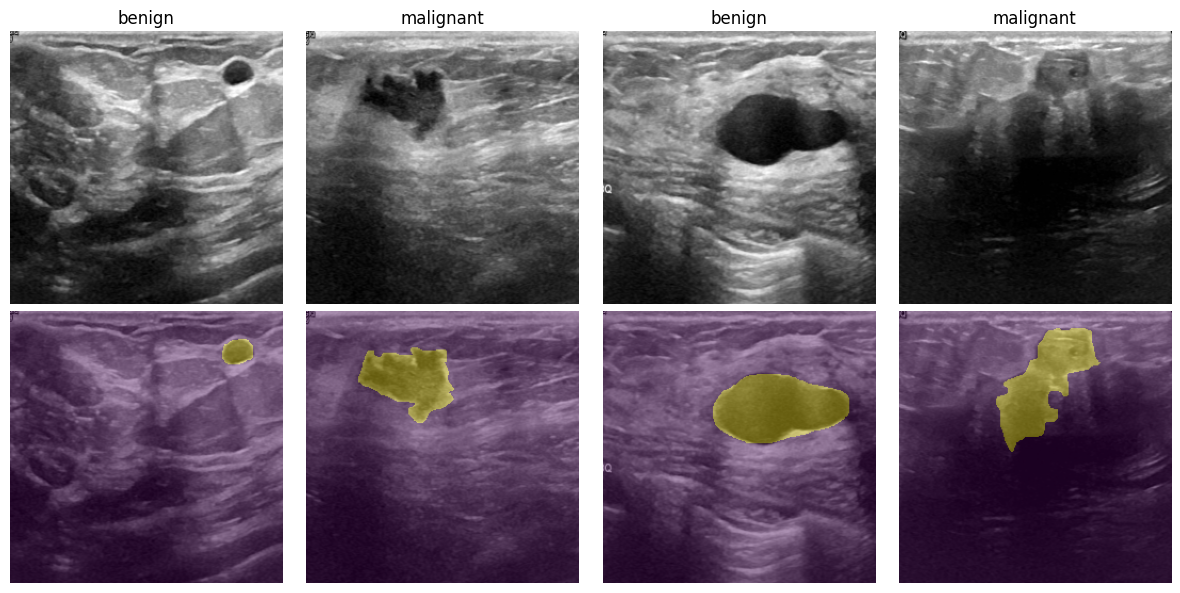

In [ ]:
# visual check of images and merged reference masks
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
sample = busi[busi["class"] != "normal"].sample(4, random_state=SEED)
for j, (_, r) in enumerate(sample.iterrows()):
    img = load_image_gray(r["image"], CONFIG["img_size"])
    msk = load_merged_mask(r["masks"], CONFIG["img_size"])
    ax[0, j].imshow(img, cmap="gray"); ax[0, j].set_title(r["class"]); ax[0, j].axis("off")
    ax[1, j].imshow(img, cmap="gray"); ax[1, j].imshow(msk, alpha=0.4); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

## 5. Segmentation data and splits

In [ ]:
from sklearn.model_selection import train_test_split

# Segmentation uses benign and malignant images (normal images have empty masks).
seg_df = busi[busi["class"] != "normal"].reset_index(drop=True)
labels = (seg_df["class"] == "malignant").astype(int)

trainval_idx, test_idx = train_test_split(
    seg_df.index, test_size=CONFIG["test_frac"], stratify=labels, random_state=SEED)
train_idx, val_idx = train_test_split(
    trainval_idx, test_size=CONFIG["val_frac"], stratify=labels[trainval_idx],
    random_state=SEED)
print(f"train={len(train_idx)} val={len(val_idx)} test={len(test_idx)}")

import albumentations as A
SEG_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
SEG_STD  = np.array([0.229, 0.224, 0.225], np.float32)

# training-time augmentation
TRAIN_AUG = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.Rotate(limit=20, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.RandomBrightnessContrast(0.2, 0.2, p=0.5),
    A.RandomGamma(p=0.3),
    A.GaussNoise(p=0.2),
])

def seg_normalize(img3_uint8):
    x = img3_uint8.astype(np.float32) / 255.0
    x = (x - SEG_MEAN) / SEG_STD
    return x.transpose(2, 0, 1).astype(np.float32)        # 3xHxW

class SegDataset(Dataset):
    def __init__(self, df, idx, size, augment=False):
        self.df, self.idx, self.size, self.augment = df, list(idx), size, augment
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        r = self.df.loc[self.idx[i]]
        img = load_image_gray(r["image"], self.size)              # uint8 HxW
        msk = load_merged_mask(r["masks"], self.size)             # uint8 HxW {0,1}
        img3 = np.repeat(img[..., None], 3, axis=2)               # HxWx3 uint8
        if self.augment:
            aug = TRAIN_AUG(image=img3, mask=msk)
            img3, msk = aug["image"], aug["mask"]
        x = seg_normalize(img3)                                   # 3xHxW float, imagenet-normed
        y = (msk > 0).astype(np.float32)[None]
        return torch.from_numpy(x), torch.from_numpy(y)

train_loader = DataLoader(SegDataset(seg_df, train_idx, CONFIG["img_size"], True),
                          batch_size=CONFIG["batch_size"], shuffle=True)
val_loader   = DataLoader(SegDataset(seg_df, val_idx, CONFIG["img_size"]),
                          batch_size=CONFIG["batch_size"])

train=362 val=64 test=107


## 6. Segmentation model

UNet++ with an EfficientNet-B3 encoder, Focal-Tversky loss (α = 0.3, β = 0.7, γ = 1.33),
AdamW and cosine annealing for 40 epochs. If `unet_best.pt` is present it is loaded and
training is skipped; set `CONFIG["force_retrain_seg"] = True` to retrain.

In [ ]:
import segmentation_models_pytorch as smp

seg_model = getattr(smp, CONFIG["arch"])(
    encoder_name=CONFIG["encoder"], encoder_weights="imagenet",
    in_channels=3, classes=1).to(DEVICE)

_seg_ckpt = "unet_best.pt"
if os.path.exists(_seg_ckpt) and not CONFIG.get("force_retrain_seg", False):
    # reuse the trained weights
    seg_model.load_state_dict(torch.load(_seg_ckpt, map_location=DEVICE))
    seg_model.eval(); seg_history = []
    print(f"[cache] loaded segmentation weights from {_seg_ckpt} -- training skipped. "
          f"Set CONFIG['force_retrain_seg']=True to retrain from scratch.")
else:
    # Focal-Tversky with beta > alpha weights missed lesion pixels more than false positives.
    if CONFIG["seg_loss"] == "focal_tversky":
        _tv = smp.losses.TverskyLoss(mode="binary", alpha=CONFIG["tversky_alpha"],
                                     beta=CONFIG["tversky_beta"], gamma=CONFIG["tversky_gamma"])
        def criterion(out, y): return _tv(out, y)
    else:  # dice_focal
        dice_loss  = smp.losses.DiceLoss(mode="binary")
        focal_loss = smp.losses.FocalLoss(mode="binary")
        def criterion(out, y): return dice_loss(out, y) + focal_loss(out, y)
    print("segmentation loss:", CONFIG["seg_loss"])

    opt = torch.optim.AdamW(seg_model.parameters(), lr=CONFIG["lr"],
                            weight_decay=CONFIG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CONFIG["epochs"])

    def dice_score(logits, target, eps=1e-6):
        p = (torch.sigmoid(logits) > 0.5).float()
        inter = (p * target).sum((1, 2, 3))
        return ((2 * inter + eps) / (p.sum((1,2,3)) + target.sum((1,2,3)) + eps)).mean().item()

    best, seg_history = 0.0, []
    for ep in range(CONFIG["epochs"]):
        seg_model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = criterion(seg_model(x), y)
            loss.backward(); opt.step()
        sched.step()
        seg_model.eval(); ds = []
        with torch.no_grad():
            for x, y in val_loader:
                ds.append(dice_score(seg_model(x.to(DEVICE)), y.to(DEVICE)))
        vd = float(np.mean(ds))
        seg_history.append(vd)
        if vd > best:
            best = vd; torch.save(seg_model.state_dict(), _seg_ckpt)
        print(f"epoch {ep+1}/{CONFIG['epochs']}  val_dice={vd:.3f}  lr={sched.get_last_lr()[0]:.2e}")
    print("best val dice:", round(best, 3))
    seg_model.load_state_dict(torch.load(_seg_ckpt))


[cache] loaded segmentation weights from unet_best.pt -- training skipped. Set CONFIG['force_retrain_seg']=True to retrain from scratch.


In [ ]:
# Segmentation metrics on the held-out test set, computed per image via predict_mask
# (so they match the masks the downstream radiomics actually uses).
from scipy import ndimage

def clean_mask(m, min_frac=0.002):
    # fill holes and drop tiny speckle components, but keep multiple real lesions
    m = ndimage.binary_fill_holes(m).astype(np.uint8)
    lbl, n = ndimage.label(m)
    if n == 0: return m
    sizes = ndimage.sum(m, lbl, range(1, n+1))
    keep = np.zeros_like(m)
    for i, s in enumerate(sizes, 1):
        if s >= min_frac * m.size: keep[lbl == i] = 1
    return keep

@torch.no_grad()
def predict_mask(img_gray_uint8, size):
    im = cv2.resize(img_gray_uint8, (size, size))
    x = torch.from_numpy(seg_normalize(np.repeat(im[..., None], 3, axis=2)))[None].to(DEVICE)
    flip_sets = [[], [3], [2], [2, 3]] if CONFIG["seg_tta"] else [[]]
    probs = []
    for f in flip_sets:
        xi = torch.flip(x, dims=f) if f else x
        o = seg_model(xi)
        o = torch.flip(o, dims=f) if f else o
        probs.append(torch.sigmoid(o))
    p = torch.stack(probs).mean(0)[0, 0].cpu().numpy()
    return clean_mask((p > 0.5).astype(np.uint8))

def dice_iou(gt, pr, eps=1e-6):
    inter = float((gt * pr).sum()); s = float(gt.sum() + pr.sum())
    union = s - inter
    return (2*inter + eps)/(s + eps), (inter + eps)/(union + eps)

seg_model.eval()
test_dice, test_iou = [], []
for i in test_idx:
    row = seg_df.loc[i]
    img = load_image_gray(row["image"], CONFIG["img_size"])
    gt  = load_merged_mask(row["masks"], CONFIG["img_size"])
    d, j = dice_iou(gt, predict_mask(img, CONFIG["img_size"]))
    test_dice.append(d); test_iou.append(j)
test_dice = np.array(test_dice); test_iou = np.array(test_iou)
print(f"TEST Dice: mean={test_dice.mean():.3f}  median={np.median(test_dice):.3f}  "
      f"IQR=[{np.percentile(test_dice,25):.3f}, {np.percentile(test_dice,75):.3f}]")
print(f"TEST IoU : mean={test_iou.mean():.3f}  median={np.median(test_iou):.3f}")
print(f"cases with Dice<0.2 (near-misses): {int((test_dice<0.2).sum())}/{len(test_dice)}")

TEST Dice: mean=0.818  median=0.883  IQR=[0.794, 0.925]
TEST IoU : mean=0.725  median=0.790
cases with Dice<0.2 (near-misses): 4/107


## 7. Feature extraction

Each ROI is the bounding box of the mask, padded by 15%. Radiomics: 18 first-order, GLCM
and shape features (scikit-image backend). Deep features: 2048-d global-average-pooled
output of a frozen ImageNet ResNet-50. Features are cached in `CONFIG["results_dir"]`.

In [ ]:
def bbox_from_mask(mask, pad_frac):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        h, w = mask.shape; return 0, 0, w, h
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    pw, ph = int((x1-x0)*pad_frac), int((y1-y0)*pad_frac)
    h, w = mask.shape
    return max(0,x0-pw), max(0,y0-ph), min(w,x1+pw), min(h,y1+ph)

def crop_roi(img, mask, pad_frac):
    x0,y0,x1,y1 = bbox_from_mask(mask, pad_frac)
    if x1<=x0 or y1<=y0: return img
    return img[y0:y1, x0:x1]

In [ ]:
# Radiomics: PyRadiomics if installed, otherwise the scikit-image backend used for the paper
USE_PYRADIOMICS = True
try:
    import SimpleITK as sitk
    from radiomics import featureextractor
    _ex = featureextractor.RadiomicsFeatureExtractor()
    _ex.settings.update({"binWidth": 25, "force2D": True, "force2Ddimension": 0,
                         "label": 1, "normalize": True})
    _ex.disableAllFeatures()
    for f in ["firstorder","glcm","glrlm","glszm","gldm","ngtdm","shape2D"]:
        _ex.enableFeatureClassByName(f)
    print("Using PyRadiomics.")
except Exception as e:
    USE_PYRADIOMICS = False
    print("Using scikit-image fallback for radiomics:", e)

from skimage.feature import graycomatrix, graycoprops
from skimage.measure import regionprops, label as sklabel
from scipy.stats import skew, kurtosis

def radiomics_fallback(img, mask):
    vals = img[mask > 0]
    if vals.size == 0: vals = img.ravel()
    f = {"fo_mean":vals.mean(),"fo_std":vals.std(),"fo_skew":skew(vals),
         "fo_kurt":kurtosis(vals),"fo_energy":float((vals.astype(np.float64)**2).sum()),
         "fo_p10":np.percentile(vals,10),"fo_p90":np.percentile(vals,90),
         "fo_median":np.median(vals)}
    q = (img // 32).astype(np.uint8)  # 8 levels
    glcm = graycomatrix(q, [1], [0, np.pi/2], levels=8, symmetric=True, normed=True)
    for prop in ["contrast","dissimilarity","homogeneity","ASM","correlation"]:
        f[f"glcm_{prop}"] = float(graycoprops(glcm, prop).mean())
    lbl = sklabel(mask > 0)
    if lbl.max() >= 1:
        rp = max(regionprops(lbl), key=lambda r: r.area)
        f.update({"shp_area":rp.area,"shp_perimeter":rp.perimeter,
                  "shp_eccentricity":rp.eccentricity,"shp_solidity":rp.solidity,
                  "shp_extent":rp.extent})
    return f

def extract_radiomics(img_u8, mask_u8):
    if USE_PYRADIOMICS:
        try:
            si = sitk.GetImageFromArray(img_u8.astype(np.float32))
            sm = sitk.GetImageFromArray(mask_u8.astype(np.int16))
            res = _ex.execute(si, sm)
            return {k: float(v) for k, v in res.items()
                    if k.startswith("original_") and np.isscalar(v)}
        except Exception:
            pass
    return radiomics_fallback(img_u8, mask_u8)

Using scikit-image fallback for radiomics: No module named 'radiomics'


In [ ]:
# Frozen ImageNet ResNet-50 with the classification head removed (no fine-tuning)
import torchvision.models as tvm
def build_backbone(name):
    try:
        m = getattr(tvm, name)(weights="IMAGENET1K_V2")
    except Exception:
        m = getattr(tvm, name)(pretrained=True)
    m.fc = nn.Identity()
    return m.eval().to(DEVICE)

cnn = build_backbone(CONFIG["cnn_backbone"])
IMAGENET_MEAN = np.array([0.485,0.456,0.406]); IMAGENET_STD = np.array([0.229,0.224,0.225])

@torch.no_grad()
def deep_features(roi_gray_u8):
    im = cv2.resize(roi_gray_u8, (224,224)).astype(np.float32)/255.0
    im = np.repeat(im[...,None], 3, axis=2)
    im = (im - IMAGENET_MEAN) / IMAGENET_STD
    t = torch.from_numpy(im.transpose(2,0,1)[None].astype(np.float32)).to(DEVICE)
    return cnn(t)[0].cpu().numpy()

In [ ]:
def build_feature_table(df, idx_list, use_pred_mask=False, size=None):
    size = size or CONFIG["img_size"]
    rad_rows, deep_rows, labels = [], [], []
    for i in tqdm(idx_list, desc="features"):
        r = df.loc[i]
        img = load_image_gray(r["image"], size)
        mask = (predict_mask(img, size) if use_pred_mask
                else load_merged_mask(r["masks"], size))
        if mask.sum() < 10:                      # fallback if mask empty
            mask = np.ones_like(mask)
        roi_img  = crop_roi(img, mask, CONFIG["roi_pad"])
        roi_mask = crop_roi(mask, mask, CONFIG["roi_pad"])
        rad_rows.append(extract_radiomics(roi_img, roi_mask))
        deep_rows.append(deep_features(roi_img))
        labels.append(1 if r["class"] == "malignant" else 0)
    rad = pd.DataFrame(rad_rows).fillna(0.0)
    deep = pd.DataFrame(deep_rows, columns=[f"deep_{k}" for k in range(len(deep_rows[0]))])
    return rad.reset_index(drop=True), deep.reset_index(drop=True), np.array(labels)

# Features for all benign and malignant BUSI images, from predicted-mask ROIs.
# BUSI segmentation and classification share images, so internal predicted-mask results
# may be mildly optimistic; BUS-BRA (never seen by the segmenter) is the external estimate.
import joblib
_imode = "pred" if CONFIG.get("internal_use_pred_mask", False) else "gt"
_feat_cache = os.path.join(CONFIG["results_dir"], f"features_internal_{_imode}.joblib")
if os.path.exists(_feat_cache) and not CONFIG.get("force_rebuild_features", False):
    _d = joblib.load(_feat_cache)
    rad_all, deep_all, y_all = _d["rad"], _d["deep"], _d["y"]
    print(f"[cache] loaded internal features ({_imode} masks) from {_feat_cache}")
else:
    rad_all, deep_all, y_all = build_feature_table(
        seg_df, list(seg_df.index), use_pred_mask=CONFIG.get("internal_use_pred_mask", False))
    joblib.dump({"rad": rad_all, "deep": deep_all, "y": y_all}, _feat_cache)
    print(f"[cache] saved internal features -> {_feat_cache}")
print("samples:", len(y_all), "| radiomics dims:", rad_all.shape[1],
      "| deep dims:", deep_all.shape[1], "| malignant frac:", round(float(y_all.mean()), 3))

[cache] loaded internal features (pred masks) from /content/results/features_internal_pred.joblib
samples: 533 | radiomics dims: 18 | deep dims: 2048 | malignant frac: 0.362


## 8. Classifiers

Three feature sets (radiomics, frozen CNN, fusion), each fitted as
`StandardScaler → LASSO selection (inner 5-fold CV) → class-balanced logistic regression`.
The final models are trained on all BUSI samples and used for SHAP and external validation.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression, LassoCV
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.calibration import calibration_curve
from scipy.stats import norm

def align(cols_ref, df):  # ensure external/fold sets share the same feature columns
    return df.reindex(columns=cols_ref, fill_value=0.0)

def make_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("select", SelectFromModel(LassoCV(cv=5, random_state=SEED, max_iter=5000))),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ])

def metrics_at(y, p, thr=0.5):
    yhat = (np.array(p) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y, p), "sens": tp/(tp+fn+1e-9),
            "spec": tn/(tn+fp+1e-9), "acc": (tp+tn)/len(y)}

# --- DeLong test for comparing two correlated AUCs (Sun & Xu 2014) ---
def _midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5*(i+j-1)+1; i = j
    T2 = np.empty(N); T2[J] = T; return T2

def _fast_delong(preds_sorted, m):
    n = preds_sorted.shape[1]-m; k = preds_sorted.shape[0]
    tx = np.empty([k,m]); ty = np.empty([k,n]); tz = np.empty([k,m+n])
    for r in range(k):
        tx[r]=_midrank(preds_sorted[r,:m]); ty[r]=_midrank(preds_sorted[r,m:]); tz[r]=_midrank(preds_sorted[r,:])
    aucs = (tz[:,:m].sum(1)/m - (m+1)/2.0)/n
    v01 = (tz[:,:m]-tx)/n; v10 = 1.0-(tz[:,m:]-ty)/m
    return aucs, np.cov(v01)/m + np.cov(v10)/n

def delong_p(y, p1, p2):
    order = (-np.array(y)).argsort(); m = int(np.array(y)[order].sum())
    preds = np.vstack((np.array(p1)[order], np.array(p2)[order]))
    aucs, cov = _fast_delong(preds, m); l = np.array([[1, -1]])
    z = (aucs[0]-aucs[1]) / np.sqrt(l @ cov @ l.T + 1e-12)
    return float(2*norm.sf(abs(z.item())))

In [ ]:
feature_sets = {
    "radiomics": rad_all,
    "cnn":       deep_all,
    "fusion":    pd.concat([rad_all, deep_all], axis=1),
}
# Final models trained on ALL samples — used for SHAP + external validation.
models = {}
for name, X in feature_sets.items():
    models[name] = (make_model().fit(X.values, y_all), list(X.columns))
print("final models trained on", len(y_all), "samples:", list(models))

final models trained on 533 samples: ['radiomics', 'cnn', 'fusion']


## 9. Internal validation: stratified 5-fold cross-validation

The full pipeline is refitted inside every outer fold. Per-fold mean ± SD is printed; the
manuscript reports AUC on the pooled out-of-fold predictions, compared with the DeLong test.

In [ ]:
# Scaling, LASSO selection (with its own inner CV) and the classifier are fitted on the
# training partition of each outer fold only. Feature extraction is label-independent
# (frozen backbone, deterministic radiomics), so pre-computing features leaks no labels.
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=CONFIG["n_folds"], shuffle=True, random_state=SEED)
fold_metrics = {n: [] for n in feature_sets}
oof = {n: np.zeros(len(y_all)) for n in feature_sets}        # out-of-fold probabilities

for fold, (tr, te) in enumerate(skf.split(np.zeros(len(y_all)), y_all)):
    for name, X in feature_sets.items():
        m = make_model().fit(X.values[tr], y_all[tr])
        p = m.predict_proba(X.values[te])[:, 1]
        oof[name][te] = p
        fold_metrics[name].append(metrics_at(y_all[te], p))

cv_summary = pd.DataFrame([
    {"model": n, **{k: f"{pd.DataFrame(fold_metrics[n])[k].mean():.3f} "
                       f"± {pd.DataFrame(fold_metrics[n])[k].std():.3f}"
                    for k in ["AUC", "sens", "spec", "acc"]}}
    for n in feature_sets])
cv_results = pd.concat(
    [pd.DataFrame(fold_metrics[n]).assign(model=n, fold=range(len(fold_metrics[n])))
     for n in feature_sets], ignore_index=True)

print(f"=== {CONFIG['n_folds']}-fold CV (mean ± std) ===")
print(cv_summary.to_string(index=False))
print()
print("DeLong on pooled out-of-fold predictions:")
print("  fusion vs cnn:       p =", round(delong_p(y_all, oof['fusion'], oof['cnn']), 4))
print("  fusion vs radiomics: p =", round(delong_p(y_all, oof['fusion'], oof['radiomics']), 4))

=== 5-fold CV (mean ± std) ===
    model           AUC          sens          spec           acc
radiomics 0.889 ± 0.020 0.860 ± 0.038 0.794 ± 0.045 0.818 ± 0.019
      cnn 0.891 ± 0.018 0.761 ± 0.052 0.868 ± 0.034 0.829 ± 0.016
   fusion 0.908 ± 0.017 0.777 ± 0.047 0.879 ± 0.041 0.842 ± 0.028

DeLong on pooled out-of-fold predictions:
  fusion vs cnn:       p = 0.027
  fusion vs radiomics: p = 0.1202


### Reference-mask ablation (internal)

The same cross-validation with ROIs cropped from the manual reference masks instead of the predicted masks.

In [ ]:
# Writes its own result files; nothing from the main run is overwritten.
from sklearn.model_selection import StratifiedKFold

assert CONFIG["internal_use_pred_mask"] is True, \
    "Run the main pipeline on predicted masks first; this cell adds the reference-mask arm."

rad_ref, deep_ref, y_ref = build_feature_table(
    seg_df, list(seg_df.index), use_pred_mask=False)
assert (y_ref == y_all).all(), "sample order changed between runs"

sets_ref = {"radiomics": rad_ref,
            "cnn":       deep_ref,
            "fusion":    pd.concat([rad_ref, deep_ref], axis=1)}

skf_ref = StratifiedKFold(n_splits=CONFIG["n_folds"], shuffle=True, random_state=SEED)
oof_ref = {n: np.zeros(len(y_ref)) for n in sets_ref}
for tr, te in skf_ref.split(np.zeros(len(y_ref)), y_ref):
    for name, X in sets_ref.items():
        m = make_model().fit(X.values[tr], y_ref[tr])
        oof_ref[name][te] = m.predict_proba(X.values[te])[:, 1]

ablation = pd.DataFrame([
    {"model": n,
     "reference_mask": round(roc_auc_score(y_ref, oof_ref[n]), 3),
     "predicted_mask": round(roc_auc_score(y_all, oof[n]), 3),
     "delta": round(roc_auc_score(y_ref, oof_ref[n]) - roc_auc_score(y_all, oof[n]), 3)}
    for n in ["radiomics", "cnn", "fusion"]])
print(ablation.to_string(index=False))

# empty predicted masks replaced by the full image
full = CONFIG["img_size"] ** 2
print("\nempty-mask fallbacks (internal, predicted):",
      int((rad_all["shp_area"] >= full).sum()), "of", len(rad_all))

RES = CONFIG["results_dir"]
ablation.to_csv(os.path.join(RES, "reference_mask_ablation.csv"), index=False)
pd.concat([rad_ref, deep_ref], axis=1).assign(label=y_ref).to_csv(
    os.path.join(RES, "features_all_refmask.csv"), index=False)
np.save(os.path.join(RES, "oof_refmask.npy"),
        np.vstack([oof_ref[n] for n in ["radiomics", "cnn", "fusion"]]))

    model  reference_mask  predicted_mask  delta
radiomics           0.989           0.887  0.103
      cnn           0.887           0.892 -0.004
   fusion           0.985           0.908  0.077

empty-mask fallbacks (internal, predicted): 6 of 533


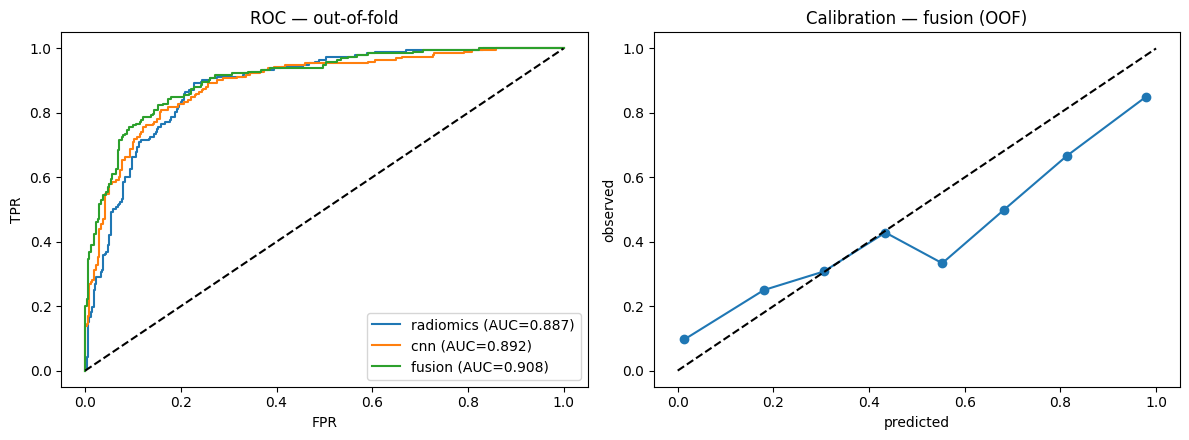

In [ ]:
RES = CONFIG["results_dir"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in oof.items():
    fpr, tpr, _ = roc_curve(y_all, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_all, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC — out-of-fold")
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ft, fp_ = calibration_curve(y_all, oof["fusion"], n_bins=8)
ax[1].plot(fp_, ft, "o-"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_title("Calibration — fusion (OOF)")
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("observed")
plt.tight_layout()
plt.savefig(os.path.join(RES, "roc_calibration_oof.png"), dpi=150, bbox_inches="tight")
plt.show()

## 10. External validation: BUS-BRA

The models trained on BUSI are applied unchanged to BUS-BRA (different scanners and
institution), with ROIs from predicted masks.

In [ ]:
import re

# ---- Manual overrides: set these ONLY if the auto-detection below fails ----
BUSBRA_IMG_DIR  = None     # e.g. "/content/busbra/Images"
BUSBRA_MASK_DIR = None     # e.g. "/content/busbra/Masks"
BUSBRA_ID_COL   = None     # e.g. "ID"
BUSBRA_PATH_COL = None     # e.g. "Pathology"

root = CONFIG["busbra_root"]
EXT = (".png", ".jpg", ".jpeg", ".bmp")

def keyify(name):
    # normalize a filename or id to a common key by stripping prefixes/extension
    s = os.path.splitext(os.path.basename(str(name)))[0].lower()
    s = re.sub(r"^(bus|mask|image|img)[_-]?", "", s)
    return s

all_imgs = [p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True)
            if os.path.isfile(p) and p.lower().endswith(EXT)]
def looks_mask(p):
    return "mask" in os.path.basename(p).lower() or (os.sep + "mask") in p.lower()
mask_files = [p for p in all_imgs if looks_mask(p)]
img_files  = [p for p in all_imgs if not looks_mask(p)]
if BUSBRA_IMG_DIR:  img_files  = [p for p in all_imgs if BUSBRA_IMG_DIR in p and not looks_mask(p)]
if BUSBRA_MASK_DIR: mask_files = [p for p in all_imgs if BUSBRA_MASK_DIR in p]

img_map  = {keyify(p): p for p in img_files}
mask_map = {keyify(p): p for p in mask_files}

print("BUS-BRA root:", root)
print("images found:", len(img_files), "| masks found:", len(mask_files))
print("sample image names:", [os.path.basename(p) for p in img_files[:3]])
print("sample mask  names:", [os.path.basename(p) for p in mask_files[:3]])
print("sample image keys :", list(img_map)[:5])

BUS-BRA root: /content/BUS_BRA DATASET
images found: 3750 | masks found: 1875
sample image names: ['bus_0857-l.png', 'bus_0982-l.png', 'bus_0326-r.png']
sample mask  names: ['mask_0467-l.png', 'mask_0417-r.png', 'mask_0662-r.png']
sample image keys : ['0857-l', '0982-l', '0326-r', '0364-r', '0983-l']


In [ ]:
csvs = glob.glob(os.path.join(root, "**", "*.csv"), recursive=True)
assert csvs, f"No CSV with labels found under {root}. Check CONFIG['busbra_root']."
bb = pd.read_csv(csvs[0])
print("CSV:", os.path.basename(csvs[0]), "| columns:", list(bb.columns))

# pick the ID column whose values best match the actual image filenames
def match_score(col):
    return bb[col].astype(str).map(keyify).isin(img_map).mean()
id_col = BUSBRA_ID_COL or max(bb.columns, key=match_score)

# pick the pathology column (the one whose values contain benign/malignant)
def is_path_col(col):
    return bb[col].astype(str).str.lower().str.contains("benign|malign").any()
path_col = BUSBRA_PATH_COL or next((c for c in bb.columns if is_path_col(c)), None)
print(f"using id_col='{id_col}' (matches {match_score(id_col):.0%} of filenames), "
      f"path_col='{path_col}'")
assert path_col, "Could not find a benign/malignant column — set BUSBRA_PATH_COL."

bb["_key"] = bb[id_col].astype(str).map(keyify)
bb["y"] = bb[path_col].astype(str).str.lower().map(
    lambda s: 1 if "malign" in s else (0 if "benign" in s else np.nan))
bb = bb.dropna(subset=["y"]); bb["y"] = bb["y"].astype(int)

import joblib
_emode = "pred" if CONFIG.get("ext_use_pred_mask", False) else "gt"
_ext_cache = os.path.join(CONFIG["results_dir"], f"features_external_{_emode}.joblib")
if os.path.exists(_ext_cache) and not CONFIG.get("force_rebuild_features", False):
    _d = joblib.load(_ext_cache)
    rad_ext, deep_ext, y_ext = _d["rad"], _d["deep"], _d["y"]
    print(f"[cache] loaded external features ({_emode} masks) from {_ext_cache}")
else:
    size = CONFIG["img_size"]
    rad_rows, deep_rows, ys = [], [], []
    skip_noimg = 0
    for _, r in tqdm(bb.iterrows(), total=len(bb), desc="busbra"):
        ip = img_map.get(r["_key"])
        if ip is None:
            skip_noimg += 1; continue
        img = load_image_gray(ip, size)
        mp = mask_map.get(r["_key"])
        use_pred = CONFIG.get("ext_use_pred_mask", False)
        mask = predict_mask(img, size) if (use_pred or mp is None) else load_merged_mask([mp], size)
        if mask.sum() < 10: mask = predict_mask(img, size)
        if mask.sum() < 10: mask = np.ones_like(mask)
        roi = crop_roi(img, mask, CONFIG["roi_pad"])
        rad_rows.append(extract_radiomics(roi, crop_roi(mask, mask, CONFIG["roi_pad"])))
        deep_rows.append(deep_features(roi)); ys.append(int(r["y"]))
    print(f"processed={len(deep_rows)} | skipped (no image match)={skip_noimg}")
    assert deep_rows, (
        "No CSV rows matched an image. Compare the printed 'sample image keys' against "
        "your id_col values, then set BUSBRA_ID_COL / BUSBRA_IMG_DIR manually above.")
    rad_ext = pd.DataFrame(rad_rows).fillna(0.0)
    deep_ext = pd.DataFrame(deep_rows, columns=[f"deep_{k}" for k in range(len(deep_rows[0]))])
    y_ext = np.array(ys)
    joblib.dump({"rad": rad_ext, "deep": deep_ext, "y": y_ext}, _ext_cache)
    print(f"[cache] saved external features -> {_ext_cache}")

fus_ext = pd.concat([rad_ext, deep_ext], axis=1)
ext_sets = {"radiomics": rad_ext, "cnn": deep_ext, "fusion": fus_ext}

print()
print("EXTERNAL test (BUS-BRA):")
rows = []
ext_probs = {}
for name, (m, cols) in models.items():
    p = m.predict_proba(align(cols, ext_sets[name]).values)[:, 1]
    ext_probs[name] = p
    rows.append({"model": name, **{k: round(v, 3) for k, v in metrics_at(y_ext, p).items()}})
external_df = pd.DataFrame(rows)
external_df.to_csv(os.path.join(CONFIG["results_dir"], "external_busbra_results.csv"), index=False)
print(external_df.to_string(index=False))
if len(np.unique(y_ext)) == 2:
    print("External DeLong  fusion vs radiomics: p =",
          round(delong_p(y_ext, ext_probs['fusion'], ext_probs['radiomics']), 4))
    print("External DeLong  fusion vs cnn:       p =",
          round(delong_p(y_ext, ext_probs['fusion'], ext_probs['cnn']), 4))

CSV: bus_data.csv | columns: ['ID', 'Case', 'Histology', 'Pathology', 'BIRADS', 'Device', 'Width', 'Height', 'Side', 'HOB', 'K5B', 'K10B', 'HOP', 'K5P', 'K10P', 'BBOX']
using id_col='ID' (matches 100% of filenames), path_col='Pathology'
[cache] loaded external features (pred masks) from /content/results/features_external_pred.joblib

EXTERNAL test (BUS-BRA):
    model   AUC  sens  spec   acc
radiomics 0.692 0.435 0.789 0.674
      cnn 0.730 0.695 0.628 0.650
   fusion 0.746 0.666 0.690 0.682
External DeLong  fusion vs radiomics: p = 0.0
External DeLong  fusion vs cnn:       p = 0.005


## 11. Interpretability

Exact linear SHAP for the fusion and radiomics-only models. Each important deep feature is described by the radiomic features it correlates with most.

140 features selected by LASSO for the fusion model


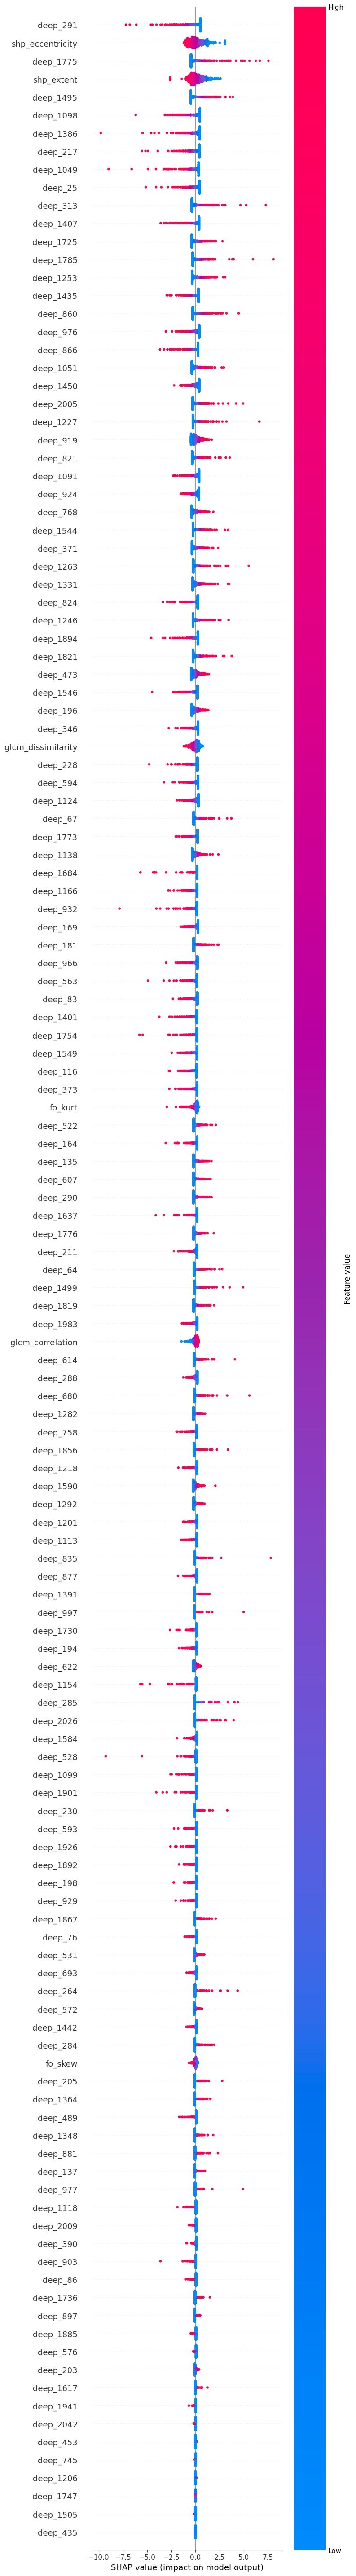

In [ ]:
import shap
from sklearn.pipeline import Pipeline

m_fus, cols_fus = models["fusion"]
X_fus = feature_sets["fusion"]
pre = Pipeline(m_fus.steps[:-1])                 # scaler + LASSO selector
clf = m_fus.named_steps["clf"]
X_t = pre.transform(X_fus.values)
selected = list(np.array(cols_fus)[m_fus.named_steps["select"].get_support()])
print(f"{len(selected)} features selected by LASSO for the fusion model")

explainer = shap.LinearExplainer(clf, X_t)       # exact + fast for linear models
try:
    shap_vals = explainer(X_t).values            # newer shap API
except Exception:
    shap_vals = explainer.shap_values(X_t)       # older shap API

shap.summary_plot(shap_vals, features=X_t, feature_names=selected,
                  max_display=len(selected), show=False)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["results_dir"], "shap_summary.png"), dpi=150, bbox_inches="tight")
plt.show()

Top 15 features by mean |SHAP|:
         feature  mean_abs_shap  modality
        deep_291       0.603155       CNN
shp_eccentricity       0.594836 radiomics
       deep_1775       0.554083       CNN
      shp_extent       0.551122 radiomics
       deep_1495       0.520805       CNN
       deep_1098       0.491165       CNN
       deep_1386       0.452458       CNN
        deep_217       0.451483       CNN
       deep_1049       0.449936       CNN
         deep_25       0.418411       CNN
        deep_313       0.409793       CNN
       deep_1407       0.388988       CNN
       deep_1725       0.382817       CNN
       deep_1785       0.377244       CNN
       deep_1253       0.373235       CNN

Modality contribution (sum of mean|SHAP|):
modality
CNN          27.2406
radiomics     1.8980
Name: mean_abs_shap, dtype: float64


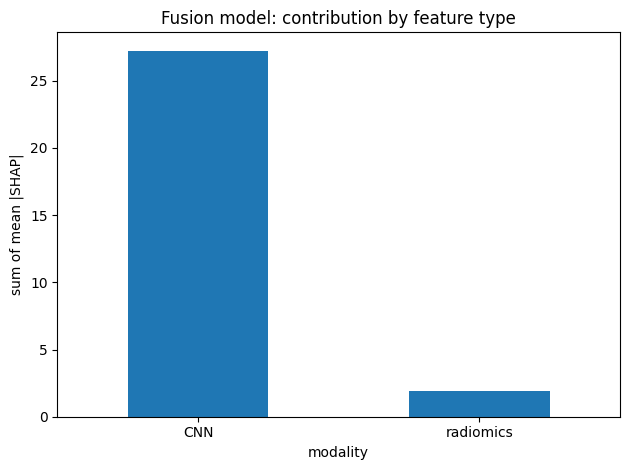

In [ ]:
# Per-feature importance and contribution by feature type
mean_abs = np.abs(shap_vals).mean(axis=0)
imp = pd.DataFrame({"feature": selected, "mean_abs_shap": mean_abs})
imp["modality"] = np.where(imp["feature"].str.startswith("deep_"), "CNN", "radiomics")
imp = imp.sort_values("mean_abs_shap", ascending=False)
imp.to_csv(os.path.join(CONFIG["results_dir"], "shap_feature_importance.csv"), index=False)

print("Top 15 features by mean |SHAP|:")
print(imp.head(15).to_string(index=False))
print()
print("Modality contribution (sum of mean|SHAP|):")
print(imp.groupby("modality")["mean_abs_shap"].sum().round(4))

ax = imp.groupby("modality")["mean_abs_shap"].sum().plot(
    kind="bar", title="Fusion model: contribution by feature type", rot=0)
ax.set_ylabel("sum of mean |SHAP|"); plt.tight_layout()
plt.savefig(os.path.join(CONFIG["results_dir"], "modality_contribution.png"), dpi=150, bbox_inches="tight")
plt.show()

15 radiomics features selected: [np.str_('fo_std'), np.str_('fo_skew'), np.str_('fo_energy'), np.str_('fo_p10'), np.str_('fo_p90'), np.str_('fo_median'), np.str_('glcm_contrast'), np.str_('glcm_homogeneity'), np.str_('glcm_ASM'), np.str_('glcm_correlation'), np.str_('shp_area'), np.str_('shp_perimeter'), np.str_('shp_eccentricity'), np.str_('shp_solidity'), np.str_('shp_extent')]


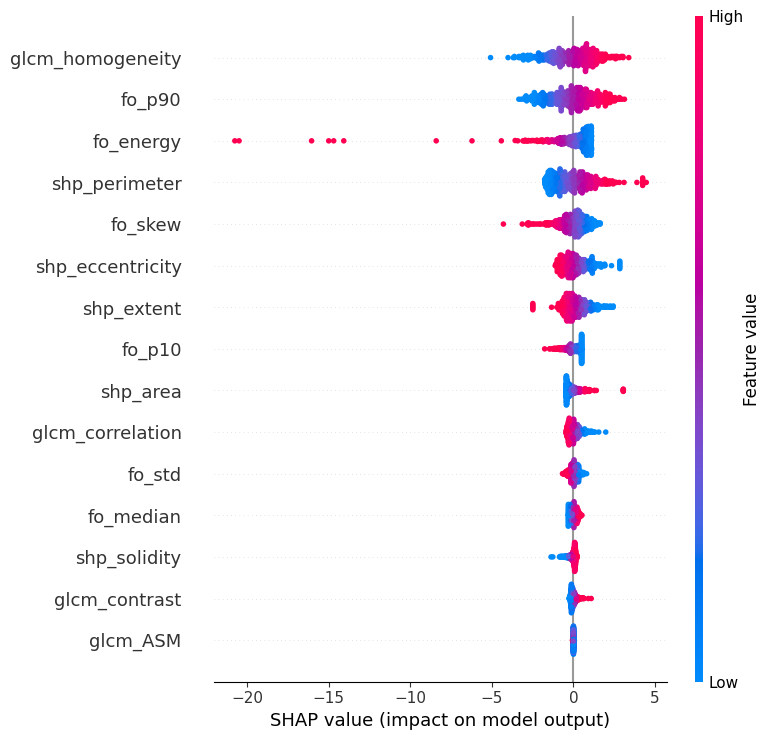

In [ ]:
# SHAP for the radiomics-only model, where every feature is named
mr, cr = models["radiomics"]
pre_r = Pipeline(mr.steps[:-1]); clf_r = mr.named_steps["clf"]
Xr_t = pre_r.transform(rad_all.values)
sel_r = list(np.array(cr)[mr.named_steps["select"].get_support()])
print(f"{len(sel_r)} radiomics features selected:", sel_r)

expl_r = shap.LinearExplainer(clf_r, Xr_t)
try:
    sv_r = expl_r(Xr_t).values
except Exception:
    sv_r = expl_r.shap_values(Xr_t)
shap.summary_plot(sv_r, features=Xr_t, feature_names=sel_r,
                  max_display=len(sel_r), show=False)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["results_dir"], "shap_radiomics.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Describe each important deep feature by the radiomic features it correlates with most
fused = feature_sets["fusion"]
rad_cols = [c for c in fused.columns if not c.startswith("deep_")]
top_deep = [f for f in imp["feature"] if f.startswith("deep_")][:10]

rows = []
for d in top_deep:
    cors = fused[rad_cols].corrwith(fused[d]).dropna()
    order = cors.abs().sort_values(ascending=False).head(3).index
    rows.append({
        "deep_feature": d,
        "behaves_like (radiomics, signed r)": ", ".join(f"{k} ({cors[k]:+.2f})" for k in order),
        "max_|r|": round(float(cors.abs().max()), 2),
    })
deep_proxy = pd.DataFrame(rows)
deep_proxy.to_csv(os.path.join(CONFIG["results_dir"], "deep_feature_proxies.csv"), index=False)
print(deep_proxy.to_string(index=False))
print()
print("Read this as: e.g. 'deep_1773 behaves like a shape/irregularity feature'.")
print("If max_|r| is low (<~0.3), that deep feature captures something the radiomics")
print("set does NOT — i.e. genuinely complementary CNN information.")

deep_feature                                          behaves_like (radiomics, signed r)  max_|r|
    deep_291                  shp_area (+0.54), fo_energy (+0.50), shp_perimeter (+0.45)     0.54
   deep_1775             shp_solidity (-0.22), shp_perimeter (+0.15), shp_extent (-0.15)     0.22
   deep_1495                  shp_perimeter (+0.30), shp_area (+0.29), fo_energy (+0.23)     0.30
   deep_1098           glcm_correlation (-0.28), glcm_contrast (+0.13), shp_area (-0.13)     0.28
   deep_1386                     fo_kurt (+0.14), fo_skew (+0.09), glcm_contrast (+0.09)     0.14
    deep_217               shp_eccentricity (-0.22), shp_area (+0.22), fo_energy (+0.18)     0.22
   deep_1049                            fo_skew (+0.15), fo_kurt (+0.12), fo_std (+0.10)     0.15
     deep_25                    glcm_correlation (-0.17), fo_std (-0.15), fo_p10 (+0.13)     0.17
    deep_313 glcm_contrast (+0.47), glcm_correlation (-0.43), glcm_dissimilarity (+0.39)     0.47
   deep_1407        

## 12. Figures

Saved as PDF and 300-dpi PNG in `CONFIG["results_dir"]`.

In [ ]:
import matplotlib as mpl
plt.rcParams.update({
    "savefig.dpi": 300, "figure.dpi": 110, "savefig.bbox": "tight",
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
    "font.family": "DejaVu Sans",
})
PALETTE = {"radiomics": "#4C72B0", "cnn": "#DD8452", "fusion": "#55A868"}
ORDER = ["radiomics", "cnn", "fusion"]
FIGDIR = CONFIG["results_dir"]

def savefig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{name}.{ext}"))
    print("saved", name)

def bootstrap_auc_ci(y, p, n=1000, seed=SEED):
    y = np.array(y); p = np.array(p); rng = np.random.default_rng(seed); aucs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2: continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return (float(np.mean(aucs)), float(np.percentile(aucs, 2.5)),
            float(np.percentile(aucs, 97.5)))

have_ext = "ext_probs" in globals() and "y_ext" in globals()

saved fig_segmentation_examples


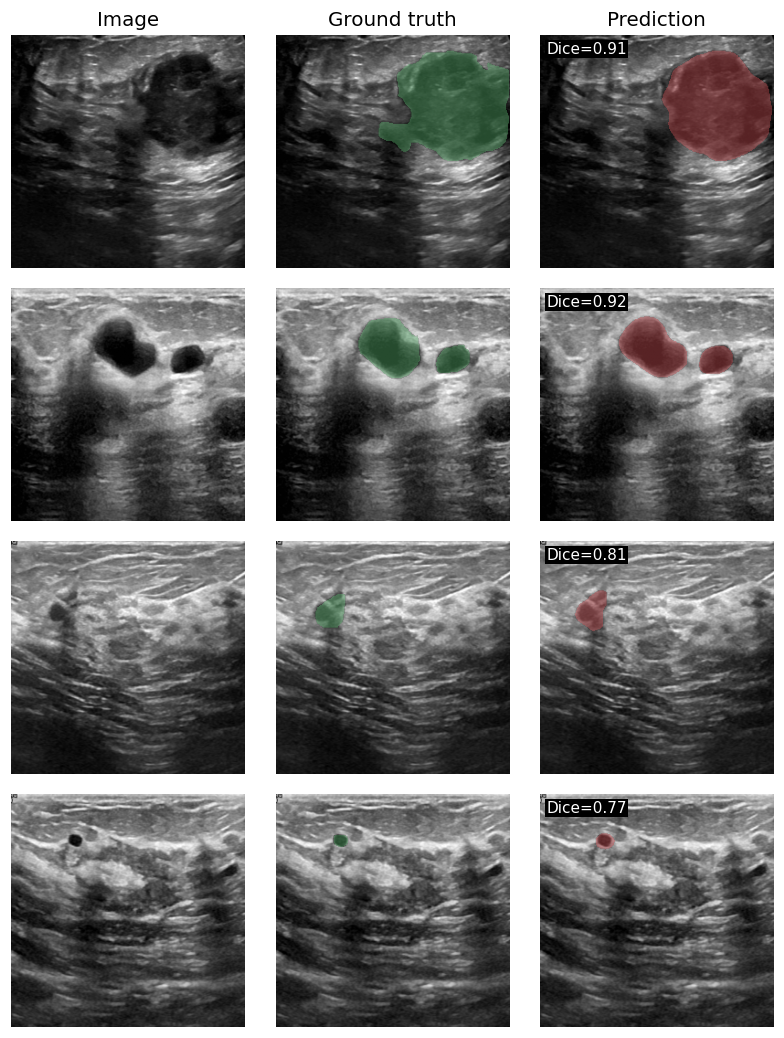

saved fig_dice_distribution


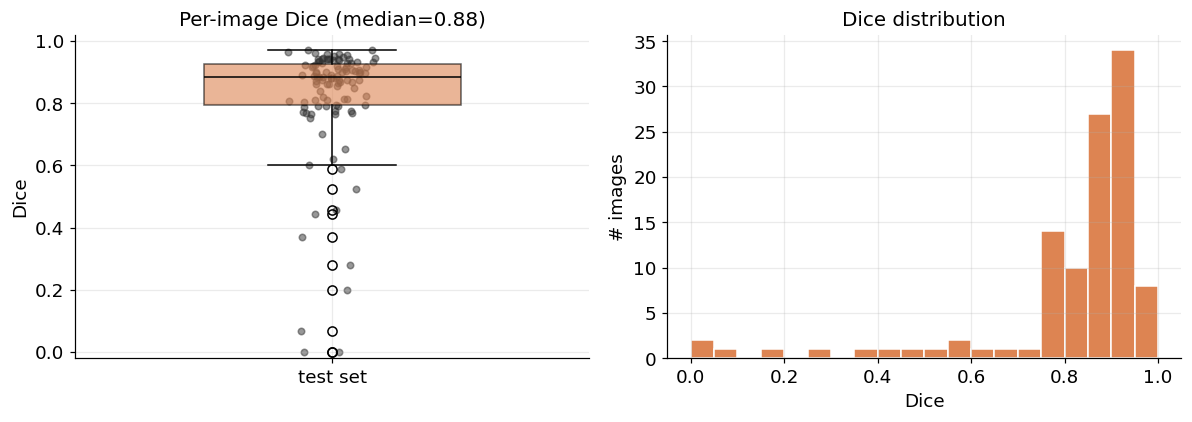

In [ ]:
# --- Fig 1: Segmentation qualitative examples ---
idxs = list(test_idx)[:4]
fig, axes = plt.subplots(len(idxs), 3, figsize=(7.5, 2.4*len(idxs)))
for r, i in enumerate(idxs):
    row = seg_df.loc[i]
    img = load_image_gray(row["image"], CONFIG["img_size"])
    gt  = load_merged_mask(row["masks"], CONFIG["img_size"])
    pr  = predict_mask(img, CONFIG["img_size"])
    d = 2*(gt*pr).sum() / (gt.sum()+pr.sum()+1e-6)
    for c, (overlay, ttl, col) in enumerate([(None,"Image",None),
                                             (gt,"Ground truth","#55A868"),
                                             (pr,"Prediction","#C44E52")]):
        axes[r, c].imshow(img, cmap="gray")
        if overlay is not None:
            axes[r, c].imshow(np.ma.masked_where(overlay == 0, overlay),
                              cmap=mpl.colors.ListedColormap([col]), alpha=0.45)
        axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(ttl)
        if c == 2:
            axes[r, c].text(6, 20, f"Dice={d:.2f}", color="white", fontsize=10,
                            bbox=dict(facecolor="black", pad=1, edgecolor="none"))
plt.tight_layout(); savefig(fig, "fig_segmentation_examples"); plt.show()

# --- Fig 2: Segmentation training curve ---
if "seg_history" in globals() and seg_history:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(range(1, len(seg_history)+1), seg_history, marker="o", color=PALETTE["fusion"])
    ax.set_xlabel("epoch"); ax.set_ylabel("validation Dice")
    ax.set_title("Segmentation training")
    savefig(fig, "fig_seg_training_curve"); plt.show()

# --- Fig 2b: Per-image Dice distribution ---
if "test_dice" in globals():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].boxplot(test_dice, vert=True, widths=0.5, patch_artist=True,
                  boxprops=dict(facecolor=PALETTE["cnn"], alpha=0.6),
                  medianprops=dict(color="black"))
    ax[0].scatter(np.random.normal(1, 0.04, len(test_dice)), test_dice,
                  s=18, color="#333", alpha=0.5)
    ax[0].set_xticks([1]); ax[0].set_xticklabels(["test set"])
    ax[0].set_ylabel("Dice"); ax[0].set_ylim(-0.02, 1.02)
    ax[0].set_title(f"Per-image Dice (median={np.median(test_dice):.2f})")
    ax[1].hist(test_dice, bins=np.linspace(0, 1, 21), color=PALETTE["cnn"], edgecolor="white")
    ax[1].set_xlabel("Dice"); ax[1].set_ylabel("# images")
    ax[1].set_title("Dice distribution")
    plt.tight_layout(); savefig(fig, "fig_dice_distribution"); plt.show()

saved fig_cv_auc


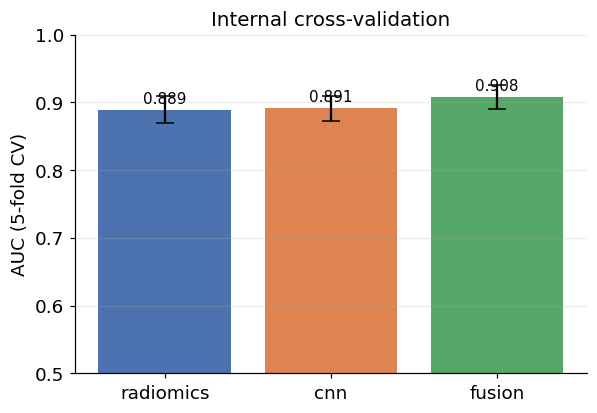

    model      set   auc    lo    hi
radiomics internal 0.887 0.858 0.914
      cnn internal 0.892 0.859 0.920
   fusion internal 0.908 0.882 0.933
radiomics external 0.692 0.667 0.715
      cnn external 0.730 0.705 0.756
   fusion external 0.746 0.723 0.769


In [ ]:
# --- Fig 3: Internal CV AUC (mean ± std across folds) ---
agg = cv_results.groupby("model")["AUC"].agg(["mean", "std"]).reindex(ORDER)
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(ORDER, agg["mean"], yerr=agg["std"], capsize=6,
              color=[PALETTE[m] for m in ORDER])
for b, mu in zip(bars, agg["mean"]):
    ax.text(b.get_x()+b.get_width()/2, mu+0.01, f"{mu:.3f}", ha="center", fontsize=10)
ax.set_ylabel(f"AUC ({CONFIG['n_folds']}-fold CV)"); ax.set_ylim(0.5, 1.0)
ax.set_title("Internal cross-validation"); ax.grid(axis="x")
savefig(fig, "fig_cv_auc"); plt.show()

# --- bootstrap CIs for internal (and external) AUC ---
ci_rows = []
for m in ORDER:
    _, lo, hi = bootstrap_auc_ci(y_all, oof[m])
    ci_rows.append({"model": m, "set": "internal",
                    "auc": roc_auc_score(y_all, oof[m]), "lo": lo, "hi": hi})
if have_ext:
    for m in ORDER:
        _, lo, hi = bootstrap_auc_ci(y_ext, ext_probs[m])
        ci_rows.append({"model": m, "set": "external",
                        "auc": roc_auc_score(y_ext, ext_probs[m]), "lo": lo, "hi": hi})
ci_df = pd.DataFrame(ci_rows)
ci_df.to_csv(os.path.join(FIGDIR, "auc_bootstrap_ci.csv"), index=False)
print(ci_df.round(3).to_string(index=False))

saved fig_internal_vs_external


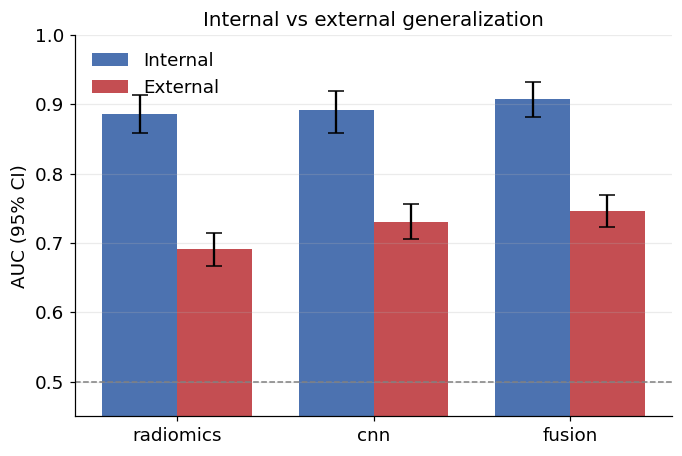

saved fig_roc_panels


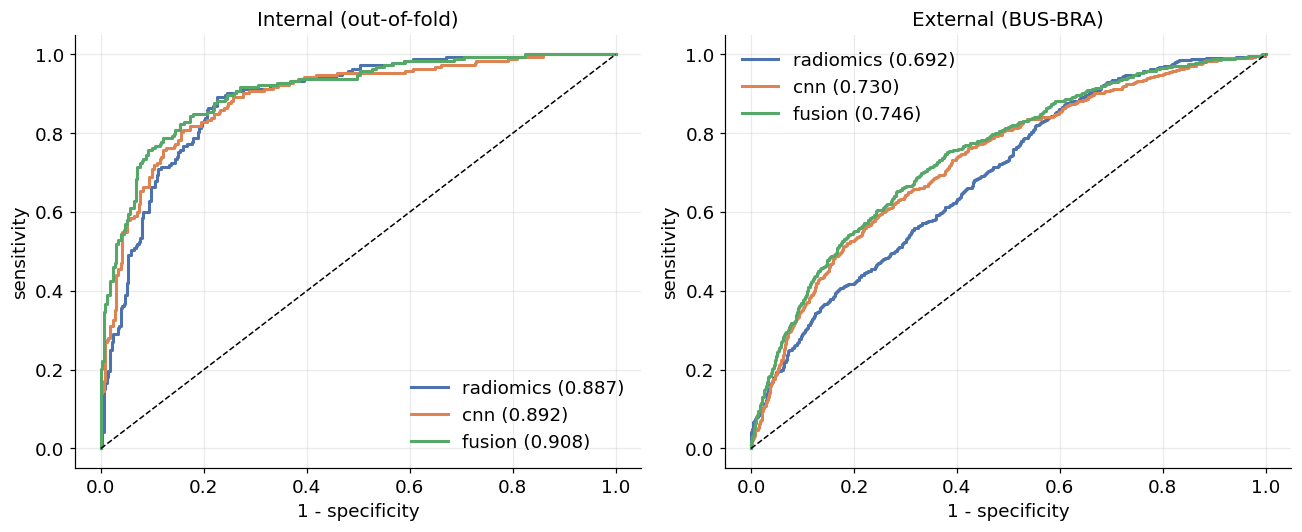

In [ ]:
# --- Fig 4: Internal vs external AUC ---
if have_ext:
    x = np.arange(len(ORDER)); w = 0.38
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for s, off, col in [("internal", -w/2, "#4C72B0"), ("external", w/2, "#C44E52")]:
        sub = ci_df[ci_df["set"] == s].set_index("model").reindex(ORDER)
        err = np.vstack([sub["auc"]-sub["lo"], sub["hi"]-sub["auc"]])
        ax.bar(x+off, sub["auc"], w, yerr=err, capsize=5, label=s.capitalize(), color=col)
    ax.axhline(0.5, ls="--", c="gray", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(ORDER); ax.set_ylabel("AUC (95% CI)")
    ax.set_ylim(0.45, 1.0); ax.legend(); ax.grid(axis="x")
    ax.set_title("Internal vs external generalization")
    savefig(fig, "fig_internal_vs_external"); plt.show()

# --- Fig 5: ROC panels (internal OOF + external) ---
ncols = 2 if have_ext else 1
fig, axes = plt.subplots(1, ncols, figsize=(6*ncols, 5), squeeze=False)
for m in ORDER:
    fpr, tpr, _ = roc_curve(y_all, oof[m])
    axes[0,0].plot(fpr, tpr, color=PALETTE[m], lw=2,
                   label=f"{m} ({roc_auc_score(y_all, oof[m]):.3f})")
axes[0,0].plot([0,1],[0,1],"k--",lw=1); axes[0,0].set_title("Internal (out-of-fold)")
axes[0,0].set_xlabel("1 - specificity"); axes[0,0].set_ylabel("sensitivity"); axes[0,0].legend()
if have_ext:
    for m in ORDER:
        fpr, tpr, _ = roc_curve(y_ext, ext_probs[m])
        axes[0,1].plot(fpr, tpr, color=PALETTE[m], lw=2,
                       label=f"{m} ({roc_auc_score(y_ext, ext_probs[m]):.3f})")
    axes[0,1].plot([0,1],[0,1],"k--",lw=1); axes[0,1].set_title("External (BUS-BRA)")
    axes[0,1].set_xlabel("1 - specificity"); axes[0,1].set_ylabel("sensitivity"); axes[0,1].legend()
plt.tight_layout(); savefig(fig, "fig_roc_panels"); plt.show()

saved fig_confusion_fusion


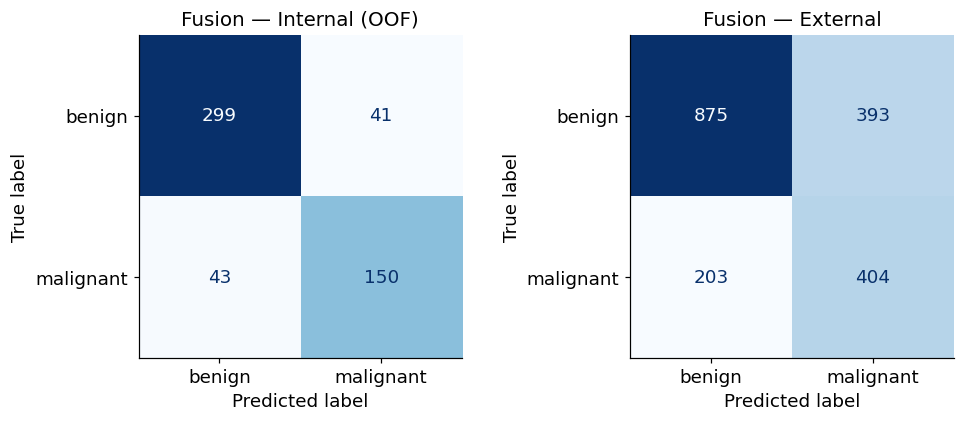

saved fig_top_features


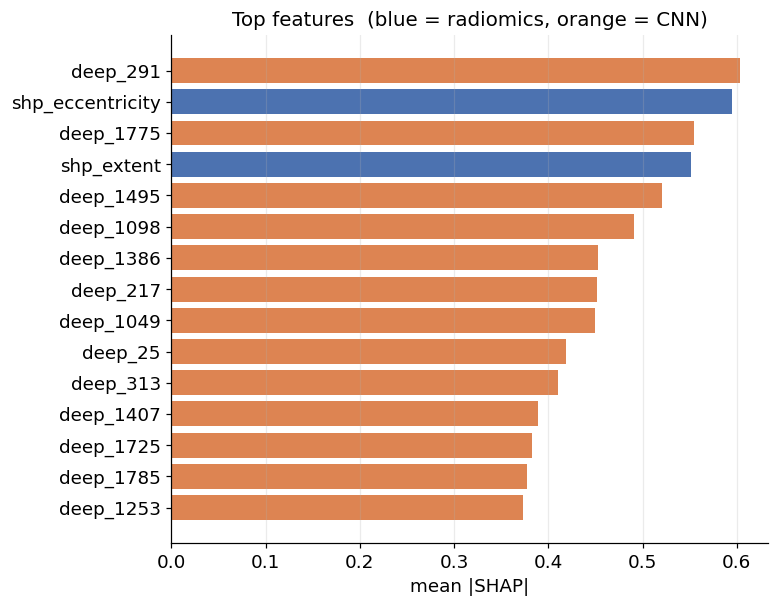

In [ ]:
# --- Fig 6: Confusion matrices for the fusion model (threshold 0.5) ---
from sklearn.metrics import ConfusionMatrixDisplay
sets = [("Internal (OOF)", y_all, oof["fusion"])]
if have_ext: sets.append(("External", y_ext, ext_probs["fusion"]))
fig, axes = plt.subplots(1, len(sets), figsize=(4.6*len(sets), 4), squeeze=False)
for k, (ttl, y, p) in enumerate(sets):
    cm = confusion_matrix(y, (np.array(p) >= 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"]).plot(
        ax=axes[0, k], colorbar=False, cmap="Blues")
    axes[0, k].set_title(f"Fusion — {ttl}"); axes[0, k].grid(False)
plt.tight_layout(); savefig(fig, "fig_confusion_fusion"); plt.show()

# --- Fig 7: Top-15 features by SHAP, coloured by modality ---
top = imp.head(15)[::-1]
colors = [PALETTE["cnn"] if f.startswith("deep_") else PALETTE["radiomics"]
          for f in top["feature"]]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top["feature"], top["mean_abs_shap"], color=colors)
ax.set_xlabel("mean |SHAP|")
ax.set_title("Top features  (blue = radiomics, orange = CNN)")
ax.grid(axis="y")
savefig(fig, "fig_top_features"); plt.show()

## 13. Save results

Feature dictionary, feature tables, CV metrics, SHAP values, trained models, segmentation weights and the configuration are written to `CONFIG["results_dir"]`.

In [ ]:
def describe(feat):
    f = feat.lower()
    if f.startswith("deep_"):
        n = feat.split("_", 1)[1]
        return ("CNN deep feature",
                f"ResNet50 penultimate-layer activation #{n} (learned, not individually interpretable)")
    if "shape" in f or f.startswith("shp_"):
        return ("Radiomics — shape", "lesion geometry: size / compactness / elongation / margin")
    if "firstorder" in f or f.startswith("fo_"):
        return ("Radiomics — first order", "intensity-histogram statistic of the lesion")
    if any(t in f for t in ["glcm","glrlm","glszm","gldm","ngtdm","texture","glcm_"]):
        return ("Radiomics — texture", "grey-level texture / heterogeneity measure")
    return ("Radiomics — other", "")

all_features = list(feature_sets["fusion"].columns)
fdict = pd.DataFrame([(f, *describe(f)) for f in all_features],
                     columns=["feature", "type", "description"])
fdict.to_csv(os.path.join(CONFIG["results_dir"], "feature_dictionary.csv"), index=False)
print(fdict["type"].value_counts())
print()
print("Interpretable (radiomics) features:")
print([f for f in all_features if not f.startswith("deep_")])

type
CNN deep feature           2048
Radiomics — first order       8
Radiomics — texture           5
Radiomics — shape             5
Name: count, dtype: int64

Interpretable (radiomics) features:
['fo_mean', 'fo_std', 'fo_skew', 'fo_kurt', 'fo_energy', 'fo_p10', 'fo_p90', 'fo_median', 'glcm_contrast', 'glcm_dissimilarity', 'glcm_homogeneity', 'glcm_ASM', 'glcm_correlation', 'shp_area', 'shp_perimeter', 'shp_eccentricity', 'shp_solidity', 'shp_extent']


In [ ]:
import json, joblib, shutil
RES = CONFIG["results_dir"]

# feature tables + labels, CV metrics, SHAP values
feature_sets["fusion"].assign(label=y_all).to_csv(os.path.join(RES, "features_all.csv"), index=False)
cv_summary.to_csv(os.path.join(RES, "cv_summary.csv"), index=False)
cv_results.to_csv(os.path.join(RES, "cv_results_per_fold.csv"), index=False)
np.save(os.path.join(RES, "shap_values.npy"), shap_vals)

# trained models (sklearn pipelines + their column order) and the U-Net weights
for name, (m, cols) in models.items():
    joblib.dump({"model": m, "columns": list(cols)}, os.path.join(RES, f"model_{name}.joblib"))
if os.path.exists("unet_best.pt"):
    shutil.copy("unet_best.pt", os.path.join(RES, "unet_best.pt"))

# config for reproducibility
with open(os.path.join(RES, "config.json"), "w") as f:
    json.dump(CONFIG, f, indent=2)

# zip everything for one-click download
zip_path = shutil.make_archive("/content/breast_us_results", "zip", RES)
print("saved to:", RES)
print("contents:", sorted(os.listdir(RES)))
print("zip:", zip_path)

if CONFIG.get("save_to_drive"):
    os.makedirs(CONFIG["drive_results"], exist_ok=True)
    shutil.copy(zip_path, CONFIG["drive_results"])
    print("copied zip to Drive:", CONFIG["drive_results"])

saved to: /content/results
contents: ['auc_bootstrap_ci.csv', 'config.json', 'cv_results_per_fold.csv', 'cv_summary.csv', 'deep_feature_proxies.csv', 'external_busbra_results.csv', 'feature_dictionary.csv', 'features_all.csv', 'features_all_refmask.csv', 'features_external_pred.joblib', 'features_internal_pred.joblib', 'fig_confusion_fusion.pdf', 'fig_confusion_fusion.png', 'fig_cv_auc.pdf', 'fig_cv_auc.png', 'fig_dice_distribution.pdf', 'fig_dice_distribution.png', 'fig_internal_vs_external.pdf', 'fig_internal_vs_external.png', 'fig_roc_panels.pdf', 'fig_roc_panels.png', 'fig_segmentation_examples.pdf', 'fig_segmentation_examples.png', 'fig_top_features.pdf', 'fig_top_features.png', 'modality_contribution.png', 'model_cnn.joblib', 'model_fusion.joblib', 'model_radiomics.joblib', 'oof_refmask.npy', 'reference_mask_ablation.csv', 'roc_calibration_oof.png', 'shap_feature_importance.csv', 'shap_radiomics.png', 'shap_summary.png', 'shap_values.npy', 'unet_best.pt']
zip: /content/breast_us_

## 14. Revision analyses

Run with the released checkpoint and feature caches. The sanity check at the top must
reproduce the published AUCs before any other number is used.

1. Segmentation of BUS-BRA by the predicted masks, against the BUS-BRA reference masks.
2. Reference-mask ablation on BUS-BRA: models trained on BUSI predicted masks tested with
   BUS-BRA predicted vs reference masks (DeLong), and models trained and tested on
   reference masks.
3. Shape-feature ablation: radiomics without the five shape features and shape features alone.

In [ ]:
import numpy as np, pandas as pd, os
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

SHAPE = [c for c in rad_all.columns if c.startswith("shp_")]
size = CONFIG["img_size"]

# ---------- 0. sanity: same models as the paper ----------
def fit_pred(Xtr, ytr, Xte):
    m = make_model().fit(Xtr.values, ytr)
    return m.predict_proba(Xte.reindex(columns=Xtr.columns, fill_value=0.0).values)[:, 1]

def oof_auc(X, y):
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(CONFIG["n_folds"], shuffle=True, random_state=SEED).split(np.zeros(len(y)), y):
        oof[te] = make_model().fit(X.values[tr], y[tr]).predict_proba(X.values[te])[:, 1]
    return roc_auc_score(y, oof)

def sets(rad, deep):
    return {"radiomics": rad, "cnn": deep, "fusion": pd.concat([rad, deep], axis=1),
            "radiomics_no_shape": rad.drop(columns=SHAPE), "shape_only": rad[SHAPE]}

S_int_pred = sets(rad_all, deep_all)
S_ext_pred = sets(rad_ext, deep_ext)
print("SANITY (must match paper):")
for n in ["radiomics", "cnn", "fusion"]:
    print(f"  {n:9s} internal OOF AUC={oof_auc(S_int_pred[n], y_all):.3f}  "
          f"external AUC={roc_auc_score(y_ext, fit_pred(S_int_pred[n], y_all, S_ext_pred[n])):.3f}")

# ---------- 1. BUS-BRA segmentation of the predicted masks ----------
seg_model.eval()
dice_e, iou_e, rad_rows, deep_rows, ys, no_mask = [], [], [], [], [], 0
for _, r in tqdm(bb.iterrows(), total=len(bb), desc="busbra ref"):
    ip = img_map.get(r["_key"])
    if ip is None:
        continue                                   # same skip rule as the main external cell
    img = load_image_gray(ip, size)
    mp = mask_map.get(r["_key"])
    if mp is None:
        no_mask += 1; continue
    gt = load_merged_mask([mp], size)
    pr = predict_mask(img, size)
    d, j = dice_iou(gt, pr); dice_e.append(d); iou_e.append(j)
    # reference-mask ROI, same fallbacks as the main pipeline
    mask = gt if gt.sum() >= 10 else np.ones_like(gt)
    roi = crop_roi(img, mask, CONFIG["roi_pad"])
    rad_rows.append(extract_radiomics(roi, crop_roi(mask, mask, CONFIG["roi_pad"])))
    deep_rows.append(deep_features(roi)); ys.append(int(r["y"]))
dice_e, iou_e = np.array(dice_e), np.array(iou_e)
print(f"\nBUS-BRA images without a reference mask: {no_mask}")
print(f"BUS-BRA Dice: mean={dice_e.mean():.3f}  median={np.median(dice_e):.3f}  "
      f"IQR=[{np.percentile(dice_e,25):.3f}, {np.percentile(dice_e,75):.3f}]  n={len(dice_e)}")
print(f"BUS-BRA IoU : mean={iou_e.mean():.3f}  median={np.median(iou_e):.3f}")
print(f"BUS-BRA Dice<0.2: {int((dice_e<0.2).sum())}/{len(dice_e)}")
assert no_mask == 0, "Some BUS-BRA images have no mask: rows no longer align with the predicted-mask features."

rad_ext_ref = pd.DataFrame(rad_rows).fillna(0.0)
deep_ext_ref = pd.DataFrame(deep_rows, columns=[f"deep_{k}" for k in range(len(deep_rows[0]))])
y_ext_ref = np.array(ys)
assert len(y_ext_ref) == len(y_ext) and (y_ext_ref == y_ext).all(), "BUS-BRA row order differs from the cached features"
S_ext_ref = sets(rad_ext_ref, deep_ext_ref)

# ---------- 2. BUSI reference-mask features (same as the internal ablation cell) ----------
rad_ref, deep_ref, y_ref = build_feature_table(seg_df, list(seg_df.index), use_pred_mask=False)
assert (y_ref == y_all).all(), "BUSI sample order changed"
S_int_ref = sets(rad_ref, deep_ref)

# ---------- 3. Ablation on BUS-BRA ----------
rows = []
for n in ["radiomics", "cnn", "fusion", "radiomics_no_shape", "shape_only"]:
    p_pp = fit_pred(S_int_pred[n], y_all, S_ext_pred[n])   # trained pred, tested pred (deployed)
    p_pr = fit_pred(S_int_pred[n], y_all, S_ext_ref[n])    # trained pred, tested ref  (better external masks only)
    p_rr = fit_pred(S_int_ref[n],  y_ref, S_ext_ref[n])    # trained ref,  tested ref  (manual masks both sides)
    rows.append({
        "model": n,
        "int_ref": round(oof_auc(S_int_ref[n], y_ref), 3),
        "int_pred": round(oof_auc(S_int_pred[n], y_all), 3),
        "ext_pred(trained pred)": round(roc_auc_score(y_ext, p_pp), 3),
        "ext_ref(trained pred)": round(roc_auc_score(y_ext, p_pr), 3),
        "ext_ref(trained ref)": round(roc_auc_score(y_ext, p_rr), 3),
        "p ext_pred vs ext_ref(trained pred)": round(delong_p(y_ext, p_pp, p_pr), 4),
    })
abl = pd.DataFrame(rows)
pd.set_option("display.width", 250)
print("\nREFERENCE vs PREDICTED MASKS, INTERNAL and BUS-BRA:")
print(abl.to_string(index=False))
abl.to_csv(os.path.join(CONFIG["results_dir"], "R2_busbra_ablation.csv"), index=False)
pd.DataFrame({"dice": dice_e, "iou": iou_e}).to_csv(
    os.path.join(CONFIG["results_dir"], "R2_busbra_dice.csv"), index=False)
print("\nsaved R2_busbra_ablation.csv and R2_busbra_dice.csv")

SANITY (must match paper):
  radiomics internal OOF AUC=0.887  external AUC=0.692
  cnn       internal OOF AUC=0.892  external AUC=0.730
  fusion    internal OOF AUC=0.908  external AUC=0.746



BUS-BRA images without a reference mask: 0
BUS-BRA Dice: mean=0.745  median=0.805  IQR=[0.675, 0.878]  n=1875
BUS-BRA IoU : mean=0.625  median=0.674
BUS-BRA Dice<0.2: 54/1875



REFERENCE vs PREDICTED MASKS, INTERNAL and BUS-BRA:
             model  int_ref  int_pred  ext_pred(trained pred)  ext_ref(trained pred)  ext_ref(trained ref)  p ext_pred vs ext_ref(trained pred)
         radiomics    0.989     0.887                   0.692                  0.743                 0.858                               0.0000
               cnn    0.887     0.892                   0.730                  0.796                 0.765                               0.0000
            fusion    0.985     0.908                   0.746                  0.792                 0.878                               0.0000
radiomics_no_shape    0.837     0.853                   0.584                  0.611                 0.628                               0.0012
        shape_only    0.990     0.845                   0.770                  0.877                 0.891                               0.0000

saved R2_busbra_ablation.csv and R2_busbra_dice.csv
